# 2016 — Graph Convolutional Networks (GCN)

**Paper:** Thomas Kipf & Max Welling, *"Semi-Supervised Classification with Graph Convolutional Networks"* (2016, ICLR 2017). Earlier: Bruna et al. (2014) spectral networks; Defferrard et al. (2016) ChebNet.

Images are grids, text is a sequence, but many datasets are **graphs** (molecules, social networks, citations). A GCN layer lets each node average its neighbours' features and transform them:

$$H^{(l+1)} = \sigma\!\left(\hat D^{-1/2}\hat A\hat D^{-1/2} H^{(l)} W^{(l)}\right), \qquad \hat A = A + I$$

This is the simplest form of **message passing**. Stacking $k$ layers lets information travel $k$ hops.

**Task:** semi-supervised node classification. We build a graph with 4 communities (a stochastic block model) and noisy node features, then reveal the labels of only **2 nodes per class**. Can the graph structure spread the labels?

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
n_per, K = 60, 4
N = n_per * K
labels = torch.arange(K).repeat_interleave(n_per)
p_in, p_out = 0.12, 0.008
same = labels[:, None] == labels[None, :]
A = (torch.rand(N, N) < torch.where(same, p_in, p_out)).float()
A = torch.triu(A, 1); A = A + A.T                                       # undirected, no self loops
centers = torch.randn(K, 16)
X = centers[labels] * 0.4 + torch.randn(N, 16)                          # weakly informative features
print(f"{N} nodes, {int(A.sum() / 2)} edges, avg degree {A.sum(1).mean():.1f}")

train_idx = torch.cat([torch.where(labels == k)[0][:2] for k in range(K)])   # 2 labels per class
test_mask = torch.ones(N, dtype=torch.bool); test_mask[train_idx] = False
A, X, labels, train_idx, test_mask = A.to(device), X.to(device), labels.to(device), train_idx.to(device), test_mask.to(device)

240 nodes, 998 edges, avg degree 8.3


In [3]:
def normalize_adj(A):
    A_hat = A + torch.eye(len(A), device=A.device)
    d = A_hat.sum(1).pow(-0.5)
    return d[:, None] * A_hat * d[None, :]

class GCN(nn.Module):
    def __init__(self, d_in, d_hid, d_out, dropout=0.5):
        super().__init__()
        self.W1, self.W2 = nn.Linear(d_in, d_hid), nn.Linear(d_hid, d_out); self.dropout = dropout
    def forward(self, X, A_norm):
        h = F.relu(A_norm @ self.W1(F.dropout(X, self.dropout, self.training)))   # aggregate neighbours
        return A_norm @ self.W2(F.dropout(h, self.dropout, self.training)), h

class MLP(nn.Module):
    """Same network but ignoring the graph (identity instead of A_norm)."""
    def __init__(self, *a): super().__init__(); self.g = GCN(*a)
    def forward(self, X, A_norm): return self.g(X, torch.eye(len(X), device=X.device))

A_norm = normalize_adj(A)
def fit(model):
    seed_everything(0)
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    for epoch in range(200):
        model.train()
        loss = F.cross_entropy(model(X, A_norm)[0][train_idx], labels[train_idx])
        opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad(): out, h = model(X, A_norm)
    return (out.argmax(1)[test_mask] == labels[test_mask]).float().mean().item(), h

acc_mlp, _ = fit(MLP(16, 32, K).to(device))
acc_gcn, H = fit(GCN(16, 32, K).to(device))
print(f"test accuracy with 8 labelled nodes — MLP (features only): {acc_mlp:.3f} | GCN (features + graph): {acc_gcn:.3f}")

test accuracy with 8 labelled nodes — MLP (features only): 0.427 | GCN (features + graph): 0.996


## Hidden node embeddings

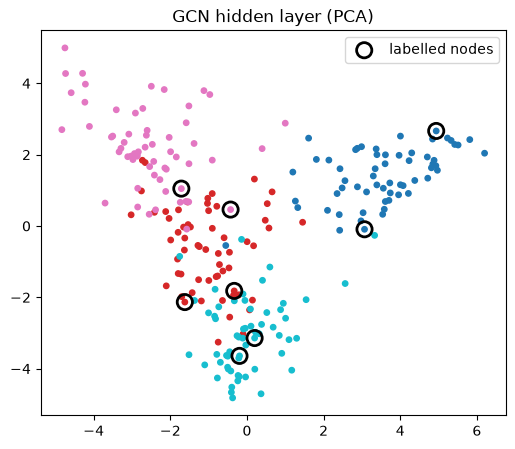

In [4]:
from sklearn.decomposition import PCA
Z = PCA(2).fit_transform(H.cpu().numpy())
plt.figure(figsize=(6, 5))
plt.scatter(Z[:, 0], Z[:, 1], c=labels.cpu(), cmap="tab10", s=15)
tr = train_idx.cpu()
plt.scatter(Z[tr, 0], Z[tr, 1], c="none", edgecolor="k", s=120, linewidths=2, label="labelled nodes")
plt.legend(); plt.title("GCN hidden layer (PCA)"); plt.show()

## Depth: over-smoothing
Each layer averages over neighbours, so with too many layers all node features become the same. This **over-smoothing** problem is why GNNs are usually shallow.

In [5]:
class DeepGCN(nn.Module):
    def __init__(self, depth, d=32):
        super().__init__()
        self.inp = nn.Linear(16, d); self.layers = nn.ModuleList([nn.Linear(d, d) for _ in range(depth - 2)]); self.out = nn.Linear(d, K)
    def forward(self, X, A_norm):
        h = F.relu(A_norm @ self.inp(X))
        for l in self.layers: h = F.relu(A_norm @ l(h))
        return A_norm @ self.out(h), h
for depth in [2, 4, 8, 16]:
    print(f"{depth:2d} layers: test acc {fit(DeepGCN(depth).to(device))[0]:.3f}")

 2 layers: test acc 0.978


 4 layers: test acc 0.978


 8 layers: test acc 0.250


16 layers: test acc 0.246
